# Explore the training metadata: Subset data

How much does our view of melanoma change when we count images instead of people? This notebook examines the cleaned training records, checks their basic quality, and describes sex, approximate age and anatomical site. These are descriptive comparisons, before fitting a model.

It follows `00_data_cleaning_d1.ipynb`, which standardised the subset records. It provides the evidence for patient grouping in `02_patient_splitting_d1.ipynb`.

Read the tables for the exact counts, then use the figures to compare the patterns. A higher observed malignancy rate describes this collection of records; it does not show that a characteristic causes melanoma or that a model can predict it accurately.

## Load the cleaned training data

Each row is one image, and several images can belong to the same patient. We load only the training metadata for this exploration.

The target records benign (`0`) or malignant (`1`). Reading it as text and checking it before integer conversion protects the counts from malformed labels: `1.5` must raise an error rather than silently becoming `1`.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
import pandas as pd

# Use this checkout's shared validation checks when run from the project or notebooks folder.
PROJECT_ROOT = next(
    (directory for directory in [Path.cwd(), *Path.cwd().parents]
     if (directory / "src" / "melanoma_detection").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the project root or its notebooks folder.")
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
from melanoma_detection.metadata_validation import validate_binary_target


# Change this one path to your local data directory.
DATA_DIR = Path(r"C:/Users/thoma/Documents/GitHub/ADS2002-Melanoma/data/subset")
TRAIN_CLEAN_PATH = DATA_DIR / "processed" / "train_clean.csv"

EXPECTED_COLUMNS = {
    "image_name",
    "patient_id",
    "sex",
    "age_approx",
    "anatom_site_general_challenge",
    "diagnosis",
    "benign_malignant",
    "target",
}

train = pd.read_csv(TRAIN_CLEAN_PATH, dtype={"age_approx": "string", "target": "string"})
missing_columns = EXPECTED_COLUMNS - set(train.columns)
if missing_columns:
    raise ValueError(f"Missing expected columns: {sorted(missing_columns)}")

train["target"] = validate_binary_target(train["target"])
print(f"Loaded: {TRAIN_CLEAN_PATH}")
print(f"Shape: {train.shape[0]:,} rows x {train.shape[1]} columns")


Loaded: C:\Users\thoma\Documents\GitHub\ADS2002-Melanoma\data\subset\processed\train_clean.csv
Shape: 6,864 rows x 8 columns


### Check that training images are present

The next cell compares image names in the metadata with JPEG filenames. `Missing JPEG files` should be zero, so every training row has a corresponding image. Files absent from the CSV are listed separately because an image file alone does not provide a labelled training record. This checks filenames, without proving that an image can be decoded or is correctly labelled.

In [2]:
JPEG_TRAIN_DIR = DATA_DIR / "train"

csv_image_names = set(train["image_name"])
jpeg_image_names = {
    path.stem
    for path in JPEG_TRAIN_DIR.iterdir()
    if path.is_file() and path.suffix.lower() in {".jpg", ".jpeg"}
}

missing_jpeg = sorted(csv_image_names - jpeg_image_names)
orphan_jpeg = sorted(jpeg_image_names - csv_image_names)

print(f"CSV image names: {len(csv_image_names):,}")
print(f"JPEG files: {len(jpeg_image_names):,}")
print(f"Missing JPEG files: {len(missing_jpeg):,}")
print(f"JPEG files absent from CSV: {len(orphan_jpeg):,}")

assert not missing_jpeg, f"Missing {len(missing_jpeg)} d1 training JPEG files."


CSV image names: 6,864
JPEG files: 6,864
Missing JPEG files: 0
JPEG files absent from CSV: 0


### Read the schema and preview

The schema lists each column's data type, the number of filled entries, and the number of distinct values. Compare the image and patient counts: many image rows can share one patient identifier. The five-row preview helps us check how the values look; five rows cannot describe the whole dataset.

In [3]:
schema = pd.DataFrame(
    {
        "dtype": train.dtypes.astype(str),
        "non_null": train.notna().sum(),
        "unique_values": train.nunique(dropna=False),
    }
)

print(schema.to_string())
train.head(5)


                                dtype  non_null  unique_values
image_name                        str      6864           6864
patient_id                        str      6864            422
sex                               str      6864              2
age_approx                     string      6864             16
anatom_site_general_challenge     str      6864              7
diagnosis                         str      6864              8
benign_malignant                  str      6864              2
target                           int8      6864              2


,image_name,patient_id,sex,age_approx,anatom_site_general_challenge,diagnosis,benign_malignant,target
0,ISIC_0015719,IP_3075186,female,45,upper extremity,unknown,benign,0
1,ISIC_0074542,IP_4698288,male,25,lower extremity,unknown,benign,0
2,ISIC_0076545,IP_9802602,male,55,upper extremity,unknown,benign,0
3,ISIC_0082348,IP_7684360,male,55,torso,unknown,benign,0
4,ISIC_0085172,IP_1705144,female,50,lower extremity,unknown,benign,0


### Check record quality

All counts below should be zero. The checks cover missing cells, duplicate image names, repeated rows, invalid targets and disagreements between the target and the benign/malignant description.

A zero missing-cell count includes the unknown labels added during cleaning. It means the fields are filled, not that every original detail is known.

In [4]:
quality_checks = pd.Series(
    {
        "missing cells": int(train.isna().sum().sum()),
        "duplicate image_name values": int(train["image_name"].duplicated().sum()),
        "exact duplicate rows": int(train.duplicated().sum()),
        "missing patient_id values": int(train["patient_id"].isna().sum()),
        "invalid target values": int((~train["target"].isin([0, 1])).sum()),
        "target/benign_malignant mismatches": int(
            (
                ((train["target"] == 1) & (train["benign_malignant"] != "malignant"))
                | ((train["target"] == 0) & (train["benign_malignant"] != "benign"))
            ).sum()
        ),
    },
    name="count",
)

print(quality_checks.to_string())
assert quality_checks.eq(0).all(), "At least one essential data-quality check failed."


missing cells                         0
duplicate image_name values           0
exact duplicate rows                  0
missing patient_id values             0
invalid target values                 0
target/benign_malignant mismatches    0


## Compare images with patients

For images, the malignant rate is malignant images divided by all images. For patients, it is people with at least one malignant image divided by all people. These answer different questions: one person can have both benign and malignant images.

The table also reports images per patient. This matters because a person with many images contributes more rows to an image-level analysis.

In [5]:
patient_summary = train.groupby("patient_id", as_index=False).agg(
    image_count=("image_name", "size"),
    malignant_images=("target", "sum"),
    distinct_targets=("target", "nunique"),
)
patient_summary["has_malignant_image"] = patient_summary["malignant_images"].gt(0)

image_malignancy_rate = train["target"].mean()
patient_malignancy_rate = patient_summary["has_malignant_image"].mean()

overview = pd.Series(
    {
        "images": len(train),
        "patients": train["patient_id"].nunique(),
        "malignant images": int(train["target"].sum()),
        "malignant image rate": image_malignancy_rate,
        "patients with >=1 malignant image": int(patient_summary["has_malignant_image"].sum()),
        "patient-level malignancy rate": patient_malignancy_rate,
        "patient minus image rate (percentage points)": 100 * (
            patient_malignancy_rate - image_malignancy_rate
        ),
        "median images per patient": patient_summary["image_count"].median(),
        "maximum images per patient": patient_summary["image_count"].max(),
        "patients containing both targets": int(patient_summary["distinct_targets"].gt(1).sum()),
    }
)
print(overview.to_string())

grain_comparison = pd.DataFrame(
    {
        "analysis_unit": ["Images", "Patients"],
        "total": [len(train), len(patient_summary)],
        "positive": [
            int(train["target"].sum()),
            int(patient_summary["has_malignant_image"].sum()),
        ],
        "malignancy_rate": [image_malignancy_rate, patient_malignancy_rate],
    }
)
grain_comparison["negative"] = grain_comparison["total"] - grain_comparison["positive"]
grain_comparison["difference_from_image_pp"] = 100 * (
    grain_comparison["malignancy_rate"] - image_malignancy_rate
)

print("\nImage-level versus patient-level comparison:")
print(
    grain_comparison.assign(
        malignancy_rate=grain_comparison["malignancy_rate"].map(lambda value: f"{value:.2%}"),
        difference_from_image_pp=grain_comparison["difference_from_image_pp"].map(
            lambda value: f"{value:+.2f}"
        ),
    ).to_string(index=False)
)


images                                          6864.000000
patients                                         422.000000
malignant images                                 128.000000
malignant image rate                               0.018648
patients with >=1 malignant image                 88.000000
patient-level malignancy rate                      0.208531
patient minus image rate (percentage points)      18.988279
median images per patient                         12.000000
maximum images per patient                       115.000000
patients containing both targets                  88.000000

Image-level versus patient-level comparison:
analysis_unit  total  positive malignancy_rate  negative difference_from_image_pp
       Images   6864       128           1.86%      6736                    +0.00
     Patients    422        88          20.85%       334                   +18.99


### Read the class-balance figure

The horizontal axis gives the share from 0% to 100%; the two rows use images and patients as their counting units. Orange represents malignant images in the image row, and patients with at least one malignant image in the patient row. Grey represents the remaining images or patients. The text beside each bar gives the positive count and total.

Compare the orange lengths to see how the denominator changes the result. A larger patient percentage does not mean more malignant images were found: it reflects counting a person once if any of their images is malignant. This figure explains why reporting image-level and patient-level rates as interchangeable would be misleading.

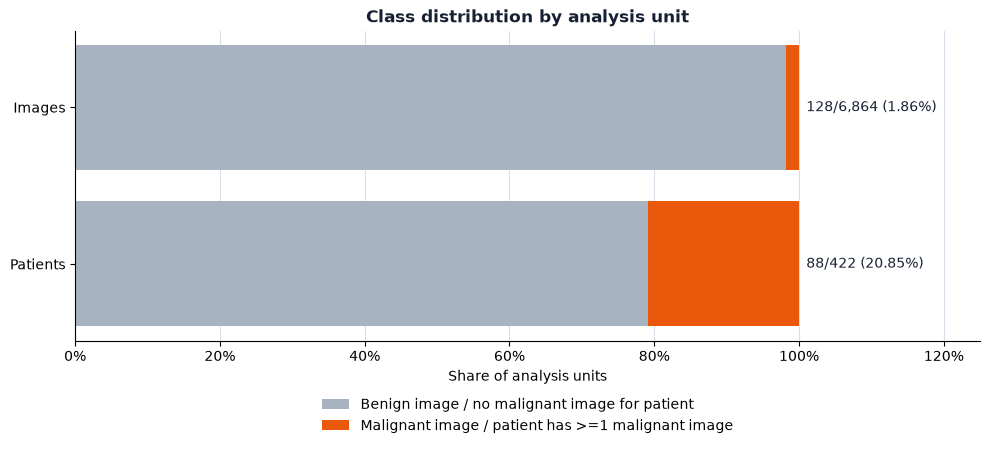

In [6]:
BLUE = "#2563EB"
ORANGE = "#EA580C"
GOLD = "#D4A72C"
INK = "#172033"
GRID = "#D9E0EA"
NEUTRAL = "#A8B3C2"

negative_share = 1 - grain_comparison["malignancy_rate"]
positive_share = grain_comparison["malignancy_rate"]
positions = np.arange(len(grain_comparison))

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.barh(
    positions,
    negative_share,
    color=NEUTRAL,
    label="Benign image / no malignant image for patient",
)
ax.barh(
    positions,
    positive_share,
    left=negative_share,
    color=ORANGE,
    label="Malignant image / patient has >=1 malignant image",
)
ax.set_yticks(positions, grain_comparison["analysis_unit"])
ax.invert_yaxis()
ax.set_title("Class distribution by analysis unit", loc="center", color=INK, weight="bold")
ax.set_xlabel("Share of analysis units")
ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, 1.25)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)

for position, row in grain_comparison.iterrows():
    ax.text(
        1.01,
        position,
        f"{int(row['positive']):,}/{int(row['total']):,} ({row['malignancy_rate']:.2%})",
        va="center",
        color=INK,
    )

ax.legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, -0.34), ncol=1)
plt.tight_layout()
plt.show()

### How many images does each patient contribute?

Read the histogram from left to right: the horizontal axis is the number of images recorded for one patient, and the height of each blue bar is the number of patients within that range. The orange dashed line marks the median, where half the patients have no more than that many images.

The figure shows whether a few patients contribute many more rows than others. A long tail to the right means that image-level results give those patients more weight. There is no better or worse bar height here; the purpose is to understand the records and plan evaluation.

Images per patient quantiles:
0.00      3.00
0.25      5.00
0.50     12.00
0.75     21.75
0.90     34.00
0.95     42.00
0.99    100.37
1.00    115.00


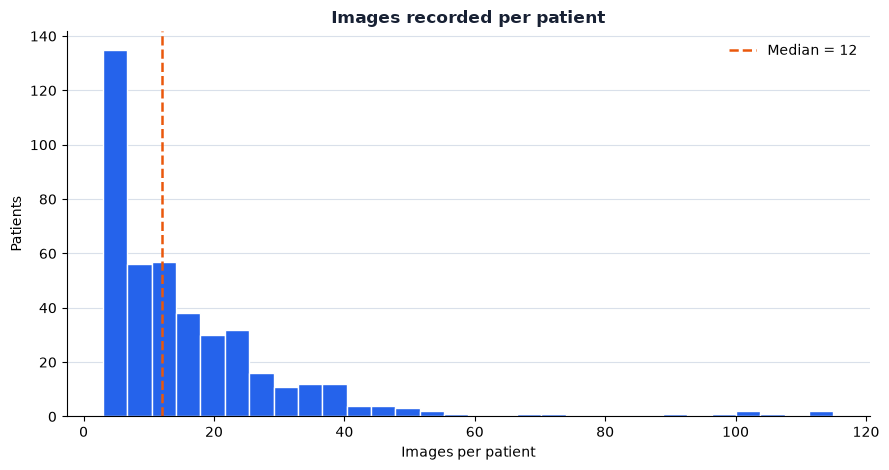

In [7]:
patient_quantiles = patient_summary["image_count"].quantile(
    [0, 0.25, 0.5, 0.75, 0.9, 0.95, 0.99, 1]
)
print("Images per patient quantiles:")
print(patient_quantiles.to_string())

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.hist(patient_summary["image_count"], bins=30, color=BLUE, edgecolor="white")
ax.axvline(
    patient_summary["image_count"].median(),
    color=ORANGE,
    linestyle="--",
    linewidth=1.8,
    label=f"Median = {patient_summary['image_count'].median():.0f}",
)
ax.set_title("Images recorded per patient", loc="center", color=INK, weight="bold")
ax.set_xlabel("Images per patient")
ax.set_ylabel("Patients")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()


### Compare sex, age and anatomical site

We calculate each category twice: once using all image rows and once counting a patient only once within that category. A patient is positive within a category if at least one of their images in that category is malignant.

Patients can appear in several age or site categories, so the category patient counts may add up to more than the total number of people. The diagnostic table reports how often this happens. These patient-category rates are descriptive checks; the models later predict the outcome of an individual image.

In [8]:
def ordered_age_categories(values: pd.Series) -> list[str]:
    unique_values = [str(value) for value in values.dropna().unique()]
    unknown_values = sorted(
        value for value in unique_values if value.casefold() == "unknown"
    )
    known_values = sorted(
        (value for value in unique_values if value.casefold() != "unknown"),
        key=lambda value: int(value),
    )
    return [*known_values, *unknown_values]


def summarise_feature(
    frame: pd.DataFrame,
    feature: str,
    order: list[str] | None = None,
) -> pd.DataFrame:
    image_summary = frame.groupby(feature, dropna=False)["target"].agg(
        image_count="size",
        malignant_images="sum",
        image_malignancy_rate="mean",
    )

    # One record per patient-category. A patient is positive in a category when
    # at least one of their images in that category is malignant.
    patient_category = (
        frame.groupby(["patient_id", feature], dropna=False, as_index=False)["target"]
        .max()
    )
    patient_summary_by_feature = patient_category.groupby(feature, dropna=False)["target"].agg(
        patient_count="size",
        malignant_patients="sum",
        patient_malignancy_rate="mean",
    )

    summary = image_summary.join(patient_summary_by_feature, how="outer")
    if order is not None:
        summary = summary.reindex(order)
    else:
        summary = summary.sort_values("image_count", ascending=False)

    summary["image_share"] = summary["image_count"] / summary["image_count"].sum()
    summary["patient_membership_share"] = (
        summary["patient_count"] / summary["patient_count"].sum()
    )
    summary["rate_difference_pp"] = 100 * (
        summary["patient_malignancy_rate"] - summary["image_malignancy_rate"]
    )
    return summary


features = ["sex", "age_approx", "anatom_site_general_challenge"]
patient_category_diagnostics = pd.DataFrame(
    {
        "patients": [train["patient_id"].nunique()] * len(features),
        "patients_in_multiple_categories": [
            int(train.groupby("patient_id")[feature].nunique().gt(1).sum())
            for feature in features
        ],
    },
    index=features,
)
print("Patients represented in multiple categories:")
print(patient_category_diagnostics.to_string())

feature_summaries = {
    "sex": summarise_feature(train, "sex"),
    "age_approx": summarise_feature(
        train,
        "age_approx",
        ordered_age_categories(train["age_approx"]),
    ),
    "anatom_site_general_challenge": summarise_feature(
        train,
        "anatom_site_general_challenge",
    ),
}

for feature, summary in feature_summaries.items():
    print(f"\n{feature}")
    printable = summary[
        [
            "image_count",
            "patient_count",
            "malignant_images",
            "malignant_patients",
            "image_malignancy_rate",
            "patient_malignancy_rate",
            "rate_difference_pp",
        ]
    ].copy()
    printable["image_malignancy_rate"] = printable["image_malignancy_rate"].map(
        lambda value: f"{value:.2%}"
    )
    printable["patient_malignancy_rate"] = printable["patient_malignancy_rate"].map(
        lambda value: f"{value:.2%}"
    )
    printable["rate_difference_pp"] = printable["rate_difference_pp"].map(
        lambda value: f"{value:+.2f}"
    )
    print(printable.to_string())


Patients represented in multiple categories:


                               patients  patients_in_multiple_categories
sex                                 422                                0
age_approx                          422                              204
anatom_site_general_challenge       422                              388



sex
        image_count  patient_count  malignant_images  malignant_patients image_malignancy_rate patient_malignancy_rate rate_difference_pp
sex                                                                                                                                      
female         3553            204                53                  37                 1.49%                  18.14%             +16.65
male           3311            218                75                  51                 2.27%                  23.39%             +21.13

age_approx
            image_count  patient_count  malignant_images  malignant_patients image_malignancy_rate patient_malignancy_rate rate_difference_pp
age_approx                                                                                                                                   
15                   18              5                 1                   1                 5.56%                  20.00%             +14.44
20   

### Read the three metadata figures

The next cell creates one figure for sex, one for age, and one for anatomical site. In each figure, the categories run down the vertical axis. Blue bars count images; gold bars count patients once within each category.

In the left panel, the horizontal axis shows each category's share. The gold shares use all patient-category memberships as their denominator, so someone recorded in several categories contributes once to each. Compare blue and gold within a category to see how multiple images per person affect its apparent size.

In the right panel, the horizontal axis shows the observed malignant percentage within each category. For gold, a patient counts as positive when they have at least one malignant image in that category. Longer bars mean a higher observed rate, not a better model or a more certain estimate. Check the preceding table's image, patient and malignant counts before interpreting a large percentage in a small group.

Use the sex figure to compare the recorded groups, the age figure to look for patterns across five-year buckets, and the site figure to compare where images were taken. The panels help choose sensible modelling questions. They do not adjust for other characteristics or provide confidence intervals, and the percentage scales can differ between figures.

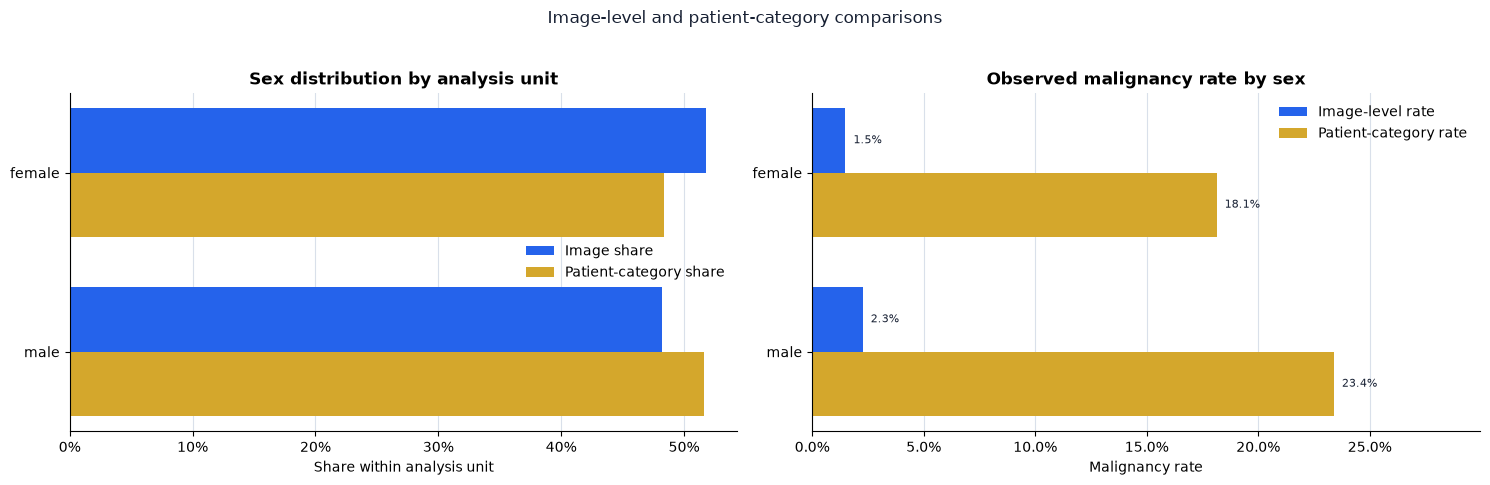

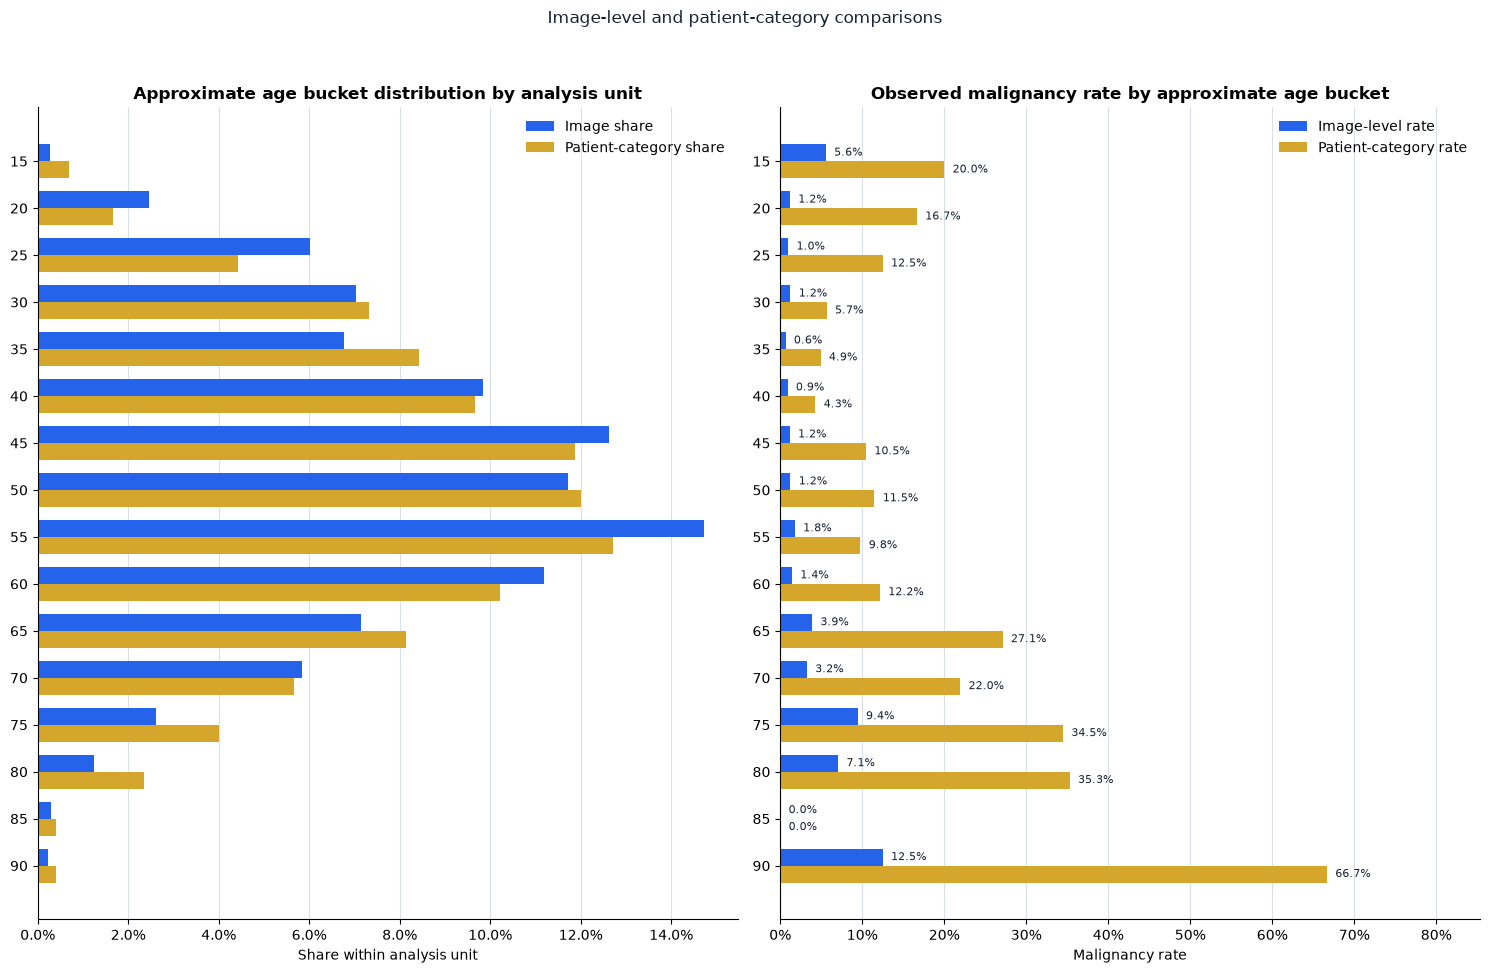

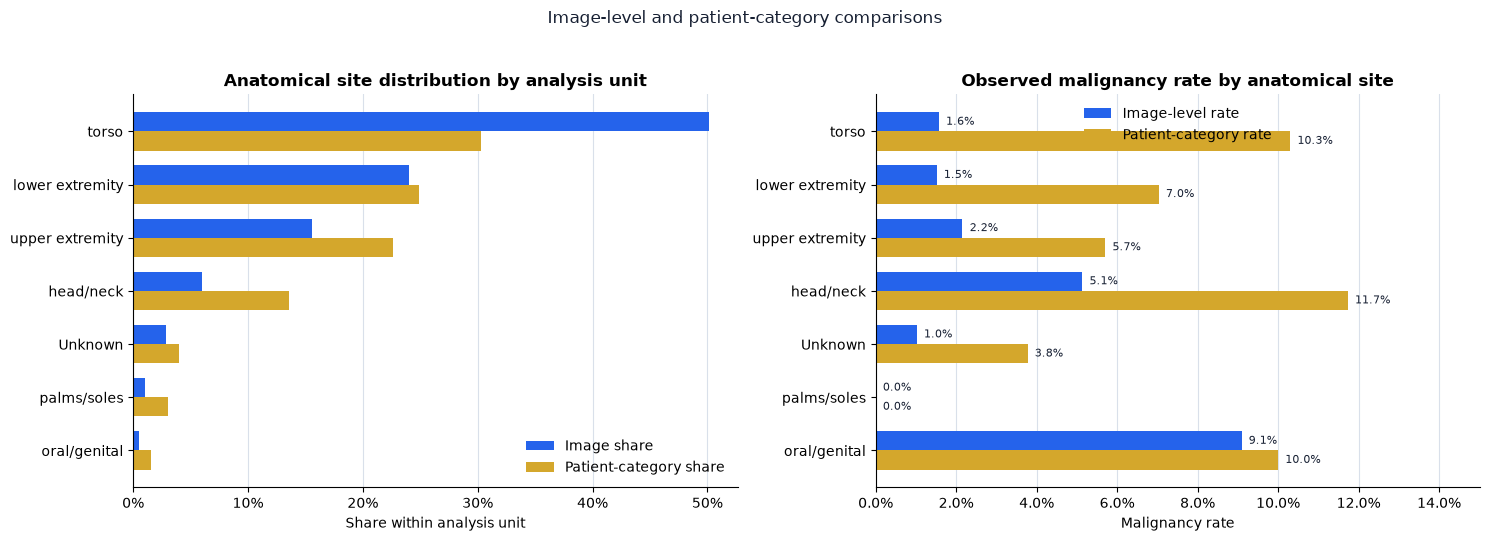

In [9]:
FEATURE_LABELS = {
    "sex": "Sex",
    "age_approx": "Approximate age bucket",
    "anatom_site_general_challenge": "Anatomical site",
}


def plot_feature_summary(feature: str, summary: pd.DataFrame) -> None:
    labels = summary.index.astype(str)
    positions = np.arange(len(summary))
    bar_height = 0.36
    height = max(4.8, 0.48 * len(summary) + 2.0)
    fig, axes = plt.subplots(1, 2, figsize=(15, height))

    axes[0].barh(
        positions - bar_height / 2,
        summary["image_share"],
        height=bar_height,
        color=BLUE,
        label="Image share",
    )
    axes[0].barh(
        positions + bar_height / 2,
        summary["patient_membership_share"],
        height=bar_height,
        color=GOLD,
        label="Patient-category share",
    )
    axes[0].set_yticks(positions, labels)
    axes[0].invert_yaxis()
    axes[0].set_title(
        f"{FEATURE_LABELS[feature]} distribution by analysis unit",
        loc="center",
        weight="bold",
    )
    axes[0].set_xlabel("Share within analysis unit")
    axes[0].xaxis.set_major_formatter(PercentFormatter(1.0))
    axes[0].legend(frameon=False)

    axes[1].barh(
        positions - bar_height / 2,
        summary["image_malignancy_rate"],
        height=bar_height,
        color=BLUE,
        label="Image-level rate",
    )
    axes[1].barh(
        positions + bar_height / 2,
        summary["patient_malignancy_rate"],
        height=bar_height,
        color=GOLD,
        label="Patient-category rate",
    )
    axes[1].set_yticks(positions, labels)
    axes[1].invert_yaxis()
    axes[1].set_title(
        f"Observed malignancy rate by {FEATURE_LABELS[feature].lower()}",
        loc="center",
        weight="bold",
    )
    axes[1].set_xlabel("Malignancy rate")
    axes[1].xaxis.set_major_formatter(PercentFormatter(1.0))
    axes[1].legend(frameon=False)

    rate_limit = max(
        summary[["image_malignancy_rate", "patient_malignancy_rate"]].max().max() * 1.28,
        0.03,
    )
    axes[1].set_xlim(0, rate_limit)
    for position, (_, row) in enumerate(summary.iterrows()):
        for offset, column in [
            (-bar_height / 2, "image_malignancy_rate"),
            (bar_height / 2, "patient_malignancy_rate"),
        ]:
            axes[1].text(
                row[column] + rate_limit * 0.012,
                position + offset,
                f"{row[column]:.1%}",
                va="center",
                fontsize=8,
                color=INK,
            )

    for ax in axes:
        ax.grid(axis="x", color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle(
        "Image-level and patient-category comparisons",
        x=0.5,
        y=1.0,
        ha="center",
        color=INK,
    )
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()


for feature, summary in feature_summaries.items():
    plot_feature_summary(feature, summary)


### Check diagnosis labels

Read `image_count` as the number of records with each diagnosis, and `malignancy_rate` as the percentage of those images with target `1`. This table helps check how the diagnosis labels relate to the recorded outcome.

Diagnosis and the benign/malignant description must stay out of model inputs. The melanoma diagnosis already identifies the target, so giving it to a prediction model would reveal the answer. An `unknown` diagnosis describes the detail available in this file; it does not mean the image's target is missing.

In [10]:
diagnosis_summary = (
    train.groupby("diagnosis")["target"]
    .agg(image_count="size", malignant_images="sum", malignancy_rate="mean")
    .sort_values("image_count", ascending=False)
)
diagnosis_summary["malignancy_rate"] = diagnosis_summary["malignancy_rate"].map(
    lambda value: f"{value:.2%}"
)
print(diagnosis_summary.to_string())


                      image_count  malignant_images malignancy_rate
diagnosis                                                          
unknown                      5576                 0           0.00%
nevus                        1109                 0           0.00%
melanoma                      128               128         100.00%
seborrheic keratosis           27                 0           0.00%
lichenoid keratosis            14                 0           0.00%
lentigo NOS                     8                 0           0.00%
cafe-au-lait macule             1                 0           0.00%
solar lentigo                   1                 0           0.00%


## Limitations

These patterns describe the supplied training collection. They cannot establish causes of melanoma, a person's clinical risk, or performance on new patients. Differences between categories may also reflect age, site, sex or sampling differences that these separate tables do not adjust for.

Multiple images from one person are related. Image-level percentages give people with more images more weight, and patient-category counts can include the same person in several categories. Small groups can show large percentages after only a few malignant cases; the figures do not show confidence intervals. Unknown labels keep missing information visible but do not correct its possible bias.

Filename and record checks cannot confirm image quality, clinically correct labels, or the absence of visually similar images. No prediction model is trained or evaluated here.

## Summary

The saved output describes 6,864 images from 422 patients. Malignant images make up 1.86% of the records, while 20.85% of patients have at least one malignant image. Patients contribute a median of 12 images, with a maximum of 115. The saved record-quality checks find no missing cells, duplicate image names or target inconsistencies.

Retain the three metadata fields as candidates for later models, while keeping diagnosis and the benign/malignant description out of the inputs. This exploration provides no model-selection result. The difference between image and patient rates, and the repeated images per person, support keeping each patient's images together during evaluation.

Next, use `02_patient_splitting_d1.ipynb` to create shared patient-grouped folds before comparing models.